# Urban Heat Island (UHI) Benchmark Notebook 

## Challenge Overview

<p align="justify">Welcome to the EY Open Science AI & Data Challenge 2025! The objective of this challenge is to build a machine learning model to predict urban heat island (UHI) hotspots in a city. By the end of the challenge, you will have developed a regression model capable of predicting the intensity of the UHI effect.

Participants will be given ground-level air temperature data in an index format, which was collected on 24th July 2021 on traverse points in the Bronx and Manhattan regions of New York city. This dataset constitutes traverse points (latitude and longitude) and their corresponding UHI (Urban Heat Island) index values. Participants will use this dataset to build a regression model to predict UHI index values for a given set of locations. It is important to understand that the UHI Index at any given location is indicative of the relative temperature elevation at that specific point compared to the city's average temperature.

This challenge is designed for participants with varying skill levels in data science and programming, offering a great opportunity to apply your knowledge and enhance your capabilities in the field.</p>

<b>Challenge Aim: </b><p align="justify"> <p>

<p align="justify">In this notebook, we will demonstrate a basic model workflow that can serve as a starting point for the challenge. The basic model has been constructed to predict the Urban Heat Island (UHI) index using features from the Sentinel-2 satellite dataset as predictor variables. In this demonstration, we utilized three features from the Sentinel-2 dataset: band B01 (Coastal Aerosol), band B06 (Red Edge), and NDVI (Normalized Difference Vegetation Index) derived from bands B04 (Red) and B08 (Near Infrared). A random forest regression model was then trained using these features.
    
These features were extracted from a GeoTIFF image created by the Sentinel-2 sample notebook. For the sample model shown in this notebook, data from a single day (24th July 2021) was considered, assuming that the values of bands B01, B04, B06, and B08 for this specific date are representative of the UHI index behavior at any location. Participants should review the details of the Sentinel-2 sample notebook to gain an understanding of the data and options for modifying the output product. 
    
</p>

<p align="justify">Most of the functions presented in this notebook were adapted from the <a href="https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a#Example-Notebook">Sentinel-2-Level-2A notebook</a> found in the Planetary Computer portal.</p>

<p align="justify">Please note that this notebook is just a starting point. We have made many assumptions in this notebook that you may think are not best for solving the challenge effectively. You are encouraged to modify these functions, rewrite them, or try an entirely new approach.</p>


## Load In Dependencies

To run this demonstration notebook, you will need to have the following packages imported below installed. This may take some time.  

In [367]:
# Supress Warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
import numpy as np
import pandas as pd

# Multi-dimensional arrays and datasets
import xarray as xr

# Geospatial raster data handling
import rioxarray as rxr

# Geospatial data analysis
import geopandas as gpd

# Geospatial operations
import rasterio
from rasterio import windows  
from rasterio import features  
from rasterio import warp
from rasterio.warp import transform_bounds 
from rasterio.windows import from_bounds 

# Image Processing
from PIL import Image

# Coordinate transformations
from pyproj import Proj, Transformer, CRS

# Feature Engineering
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Machine Learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Planetary Computer Tools
import pystac_client
import planetary_computer as pc
from pystac.extensions.eo import EOExtension as eo

# Others
import os
from tqdm import tqdm



## Response Variable

Before building the model, we need to load in the Urban Heat Island (UHI) index training dataset. We have curated data for the New York region. The dataset consists of geo-locations (Longitude and Latitude), with additional fields including date & time of data collection and the UHI index for each location. 

In [368]:
# Load the training data from csv file and display the first few rows to inspect the data
ground_df = pd.read_csv("Training_data_uhi_index.csv")
ground_df.head()

,Longitude,Latitude,datetime,UHI Index
0,-73.909167,40.813107,24-07-2021 15:53,1.030289
1,-73.909187,40.813045,24-07-2021 15:53,1.030289
2,-73.909215,40.812978,24-07-2021 15:53,1.023798
3,-73.909242,40.812908,24-07-2021 15:53,1.023798
4,-73.909257,40.812845,24-07-2021 15:53,1.021634


In [369]:
# # Find the 4 highest UHI Index values
# top_4_outliers = ground_df.nlargest(4, 'UHI Index')

# print("Top 4 outliers to be removed:")
# print(top_4_outliers[['Longitude', 'Latitude', 'UHI Index']])
# print(f"\nNumber of outliers being removed: 4 rows")

# # Get the threshold value of the 4th highest outlier
# threshold = top_4_outliers['UHI Index'].min()

# # Filter out only the top 4 outliers
# ground_df = ground_df[ground_df['UHI Index'] < threshold]

# print("\nSummary statistics after removing top 4 outliers:")
# print(ground_df['UHI Index'].describe())


## Predictor Variables

<p align="justify">Now that we have our UHI data, it is time to gather the predictor variables from the Sentinel-2 dataset. Participants should review the provided Sentinel-2 sample notebook as it was used to create a sample GeoTIFF for this models. For a more in-depth look regarding the Sentinel-2 dataset and how to query it, see the Microsoft Planetary Computer example <a href="https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a#Example-Notebook">Sentinel-2 supplementary notebook</a>. </p>

<p align="justify">Sentinel-2 optical data provides high-resolution imagery that is sensitive to land surface characteristics, which are crucial for understanding urban heat dynamics. Band values such as B01 (Coastal aerosol), B06 (Red Edge), and NDVI (Normalized Difference Vegetation Index) derived from B04 (Red) and B08 (Near Infrared) help us in estimating the UHI index. Hence, we are choosing B01, B06, and NDVI as predictor variables for this experiment.</p>

<ul> 
<li>B01 - Reflectance values from the Coastal aerosol band, which help in assessing aerosol presence and improving atmospheric correction.</li>

<li>B06 - Reflectance values from the Red Edge band, which provide useful information for detecting vegetation, water bodies, and urban surfaces.</li>

<li>NDVI - Derived from B04 (Red) and B08 (Near Infrared), NDVI is an important indicator for vegetation health and land cover.</li>
</ul>


<h4 style="color:rgb(255, 255, 0)"><strong>Tip 1</strong></h4>
<p align="justify">Participants might explore other combinations of bands from the Sentinel-2 and from other satellite datasets as well. For example, you can use mathematical combinations of bands to generate various indices </a> which can then be used as features in your model. These bands or indices may provide insights into surface characteristics, vegetation, or built-up areas that could influence UHI patterns.

### Analyze the Sentinel-2 Data

<p align="justify">To obtain the Sentinel-2 data, we created a GeoTIFF image for a specific date and area of interest, which in this case is the Bronx and Manhattan regions of New York. The GeoTIFF product allows us to extract the relevant band values. In this example, we extracted B01 (Coastal Aerosol), B04 (Red), B06 (Red Edge), and B08 (Near Infrared) values for a single day (24th July, 2021). Participants should review the provided Sentinel-2 sample notebook for common output images (RGB, NDVI) and methods to alter the output.</p>

### Methods of Extracting Band Values from Sentinel-2 Data

There are two common methods to extract band values from Sentinel-2 data:

<ul>
    <li><strong>Using API Calls:</strong> Retrieve band values directly from Sentinel-2 datasets via APIs, such as the <code>planetary_computer</code>.</li>
</ul>
<ul>
    <li><strong>Using GeoTIFF Images:</strong> Create and download a GeoTIFF image containing the desired bands and extract the band values locally. The GeoTIFF image can represent any desired time period (single date or time series mosaic) and include any number of spectral bands.</li>
</ul>

Participants can select any of these approaches as per their convenience. Since our dataset is large, the API method can be time-consuming and resource-intensive. Therefore, in this sample notebook, we have opted for the second method and extracted the values for bands B01, B04, B08, and B06. Please refer to the Sentinel-2 sample notebook for details about the creation of the GeoTIFF image. 

<h4 style="color:rgb(255, 255, 0)"><strong>Tip 2</strong></h4>
<p align="justify"> Rather than extracting the bands for a single day coincident with the ground-based data collection, participants might explore other options to improve data quality. For example, one could select a different single date with minimal or no cloud cover or generate a median mosaic using several scenes within a time series. See the Sentinel-2 sample notebook for examples.</p>

### Downloading GeoTIFF Image

For building a sample model in this demonstration notebook, we have downloaded a GeoTIFF file locally for a single day (24th July 2021). The file is named <b>S2_sample.tiff</b>. This GeoTIFF file contains values of four bands: Band B01, Band B04, Band B06 and Band B08. In the subsequent section, we will use this GeoTIFF file to extract the band values for the geo-locations given in the training dataset to create the features.

First, let’s visualize the bands of the downloaded GeoTIFF image.

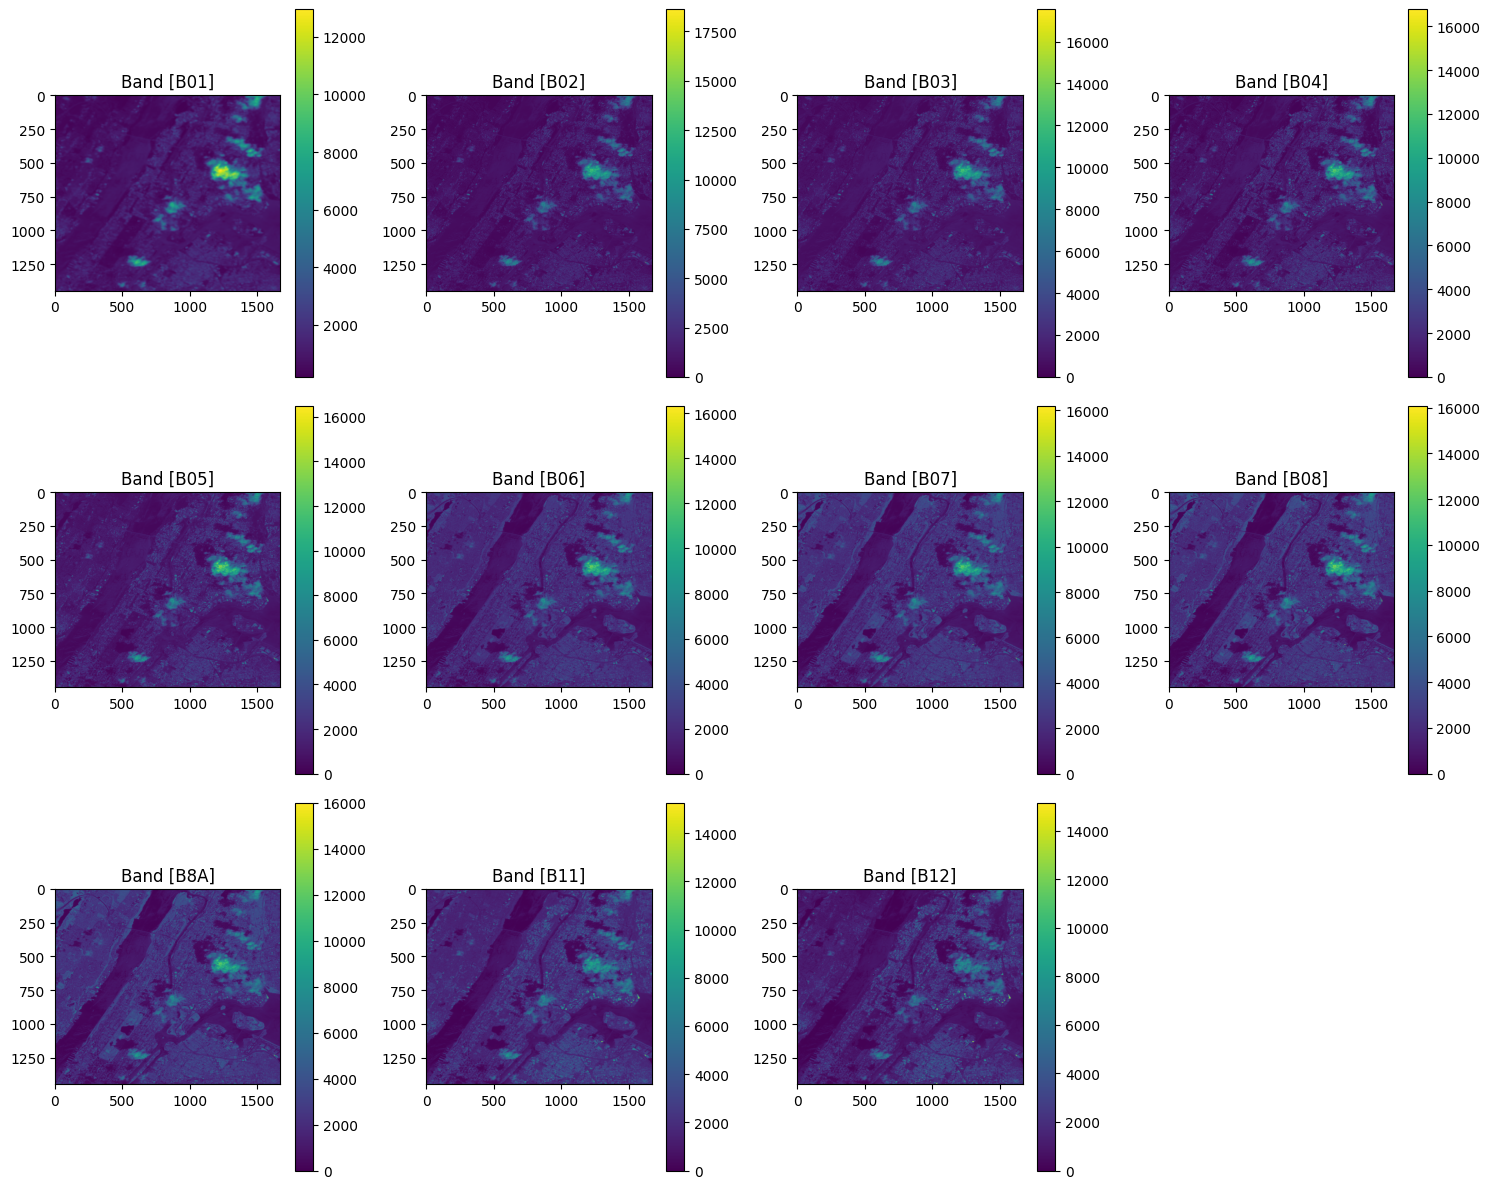

In [370]:
# Reads and plots all bands from the GeoTIFF file.

# Open the GeoTIFF file
tiff_path = "S2_sample.tiff"

# Read all bands from the GeoTIFF file
with rasterio.open(tiff_path) as src1:
    band1 = src1.read(1)   # Band [B01] 
    band2 = src1.read(2)   # Band [B02]
    band3 = src1.read(3)   # Band [B03]
    band4 = src1.read(4)   # Band [B04]
    band5 = src1.read(5)   # Band [B05]
    band6 = src1.read(6)   # Band [B06]
    band7 = src1.read(7)   # Band [B07]
    band8 = src1.read(8)   # Band [B08]
    band9 = src1.read(9)   # Band [B8A]
    band10 = src1.read(10) # Band [B11]
    band11 = src1.read(11) # Band [B12]

# Create a figure with subplots for all bands
fig, axes = plt.subplots(3, 4, figsize=(15, 12))
axes = axes.flatten()

# Plot each band
bands = [band1, band2, band3, band4, band5, band6, band7, band8, band9, band10, band11]
titles = ['Band [B01]', 'Band [B02]', 'Band [B03]', 'Band [B04]', 'Band [B05]', 
         'Band [B06]', 'Band [B07]', 'Band [B08]', 'Band [B8A]', 'Band [B11]', 'Band [B12]']

for i, (band, title) in enumerate(zip(bands, titles)):
    im = axes[i].imshow(band, cmap='viridis')
    axes[i].set_title(title)
    fig.colorbar(im, ax=axes[i])

# Remove the empty subplot
axes[-1].remove()

plt.tight_layout()
plt.show()


<h4 style="color:rgb(255, 255, 0)"><strong>Tip 3</strong></h4>

Instead of a single point data extraction, participants might explore the approach of creating a focal buffer around the locations (e.g., 50 m, 100 m, 150 m etc). For example, if the specified distance was 50 m and the specified band was “Band 2”, then the value of the output pixels from this analysis would reflect the average values in band 2 within 50 meters of the specific location. This approach might help reduction in error associated with spatial autocorrelation. In this demonstration notebook, we are extracting the band data for each of the locations without creating a buffer zone.




### Extracting Band Values from the GeoTIFF Image


In [371]:
# Extracts satellite band values from a GeoTIFF based on coordinates from a csv file and returns them in a DataFrame.

def map_satellite_data(tiff_path, csv_path):
    
    # Load the GeoTIFF data
    data = rxr.open_rasterio(tiff_path)
    tiff_crs = data.rio.crs

    # Read the Excel file using pandas
    df = pd.read_csv(csv_path)
    latitudes = df['Latitude'].values
    longitudes = df['Longitude'].values

    # 3. Convert lat/long to the GeoTIFF's CRS
    # Create a Proj object for EPSG:4326 (WGS84 - lat/long) and the GeoTIFF's CRS
    proj_wgs84 = Proj(init='epsg:4326')  # EPSG:4326 is the common lat/long CRS
    proj_tiff = Proj(tiff_crs)
    
    # Create a transformer object
    transformer = Transformer.from_proj(proj_wgs84, proj_tiff)

    # Initialize lists for all bands
    B01_values = []
    B02_values = []
    B03_values = []
    B04_values = []
    B05_values = []
    B06_values = []
    B07_values = []
    B08_values = []
    B8A_values = []
    B11_values = []
    B12_values = []

    # Iterate over the latitudes and longitudes, and extract the corresponding band values
    for lat, lon in tqdm(zip(latitudes, longitudes), total=len(latitudes), desc="Mapping values"):
        # Extract values for all bands
        B01_value = data.sel(x=lon, y=lat, band=1, method="nearest").values
        B01_values.append(B01_value)
        
        B02_value = data.sel(x=lon, y=lat, band=2, method="nearest").values
        B02_values.append(B02_value)
        
        B03_value = data.sel(x=lon, y=lat, band=3, method="nearest").values
        B03_values.append(B03_value)
        
        B04_value = data.sel(x=lon, y=lat, band=4, method="nearest").values
        B04_values.append(B04_value)
        
        B05_value = data.sel(x=lon, y=lat, band=5, method="nearest").values
        B05_values.append(B05_value)
        
        B06_value = data.sel(x=lon, y=lat, band=6, method="nearest").values
        B06_values.append(B06_value)
        
        B07_value = data.sel(x=lon, y=lat, band=7, method="nearest").values
        B07_values.append(B07_value)
        
        B08_value = data.sel(x=lon, y=lat, band=8, method="nearest").values
        B08_values.append(B08_value)
        
        B8A_value = data.sel(x=lon, y=lat, band=9, method="nearest").values
        B8A_values.append(B8A_value)
        
        B11_value = data.sel(x=lon, y=lat, band=10, method="nearest").values
        B11_values.append(B11_value)
        
        B12_value = data.sel(x=lon, y=lat, band=11, method="nearest").values
        B12_values.append(B12_value)

    # Create a DataFrame with all band values
    df = pd.DataFrame()
    df['B01'] = B01_values
    df['B02'] = B02_values
    df['B03'] = B03_values
    df['B04'] = B04_values
    df['B05'] = B05_values
    df['B06'] = B06_values
    df['B07'] = B07_values
    df['B08'] = B08_values
    df['B8A'] = B8A_values
    df['B11'] = B11_values
    df['B12'] = B12_values
    
    return df


In [372]:
def map_lst_data(tiff_path, csv_path):
    """
    Extracts Land Surface Temperature (LST) values from a Landsat GeoTIFF based on coordinates.
    
    Args:
        tiff_path (str): Path to the LST GeoTIFF file
        csv_path (str): Path to CSV file containing coordinates
        
    Returns:
        DataFrame with LST values
    """
    # Load the GeoTIFF data
    data = rxr.open_rasterio(tiff_path)
    tiff_crs = data.rio.crs

    # Read the CSV file
    df = pd.read_csv(csv_path)
    latitudes = df['Latitude'].values
    longitudes = df['Longitude'].values

    # Set up coordinate transformation
    proj_wgs84 = Proj(init='epsg:4326')
    proj_tiff = Proj(tiff_crs)
    transformer = Transformer.from_proj(proj_wgs84, proj_tiff)

    # Initialize empty list for LST values
    lst_values = []

    # Extract LST values for each coordinate pair
    for lat, lon in tqdm(zip(latitudes, longitudes), total=len(latitudes), desc="Mapping values"):
        lst_value = data.sel(x=lon, y=lat, method="nearest").values
        lst_values.append(lst_value[0])  # Take first band only for LST

    # Create DataFrame with LST values
    df_lst = pd.DataFrame({'LST': lst_values})
    
    return df_lst

# Map LST data using the function
lst_data = map_lst_data('Landsat_LST.tiff', 'Training_data_uhi_index.csv')




Mapping values: 100%|██████████| 11229/11229 [00:05<00:00, 2028.24it/s]


In [373]:
# Mapping satellite data with training data.
final_data = map_satellite_data('S2_sample.tiff', 'Training_data_uhi_index.csv')

Mapping values: 100%|██████████| 11229/11229 [01:40<00:00, 111.69it/s]


In [374]:

# Join LST data to final_data
final_data = pd.concat([final_data, lst_data], axis=1)


In [375]:
final_data.head()

,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12,LST
0,846.0,1042.0,1036.0,1036.0,1272.0,1502.0,1605.0,1906.0,1638.0,1487.0,1265.0,38.393941
1,846.0,1042.0,1036.0,1036.0,1272.0,1502.0,1605.0,1906.0,1638.0,1487.0,1265.0,38.393941
2,846.0,583.0,818.0,709.0,1054.0,1668.0,2097.0,2190.0,2149.0,1465.0,991.0,37.785534
3,846.0,581.0,733.0,657.0,1054.0,1668.0,2097.0,2182.0,2149.0,1465.0,991.0,37.785534
4,846.0,655.0,744.0,745.0,1021.0,1728.0,1943.0,2112.0,2056.0,1544.0,1134.0,37.358281


In [376]:
# Calculate median NDVI (Normalized Difference Vegetation Index)
ndvi = (final_data['B08'] - final_data['B04']) / (final_data['B08'] + final_data['B04'])
ndvi = ndvi.replace([np.inf, -np.inf], np.nan)
final_data['NDVI'] = ndvi.median()

# Calculate median NDBI (Normalized Difference Built-up Index)
ndbi = (final_data['B11'] - final_data['B08']) / (final_data['B11'] + final_data['B08'])
ndbi = ndbi.replace([np.inf, -np.inf], np.nan)
final_data['NDBI'] = ndbi.median()

# Calculate median NDWI (Normalized Difference Water Index)
ndwi = (final_data['B03'] - final_data['B08']) / (final_data['B03'] + final_data['B08'])
ndwi = ndwi.replace([np.inf, -np.inf], np.nan)
final_data['NDWI'] = ndwi.median()

## Joining the predictor variables and response variables
Now that we have extracted our predictor variables, we need to join them onto the response variable . We use the function <i><b>combine_two_datasets</b></i> to combine the predictor variables and response variables.The <i><b>concat</b></i> function from pandas comes in handy here.

In [377]:
# Combine two datasets vertically (along columns) using pandas concat function.
def combine_two_datasets(dataset1,dataset2):
    '''
    Returns a  vertically concatenated dataset.
    Attributes:
    dataset1 - Dataset 1 to be combined 
    dataset2 - Dataset 2 to be combined
    '''
    
    data = pd.concat([dataset1,dataset2], axis=1)
    return data

In [378]:
# Combining ground data and final data into a single dataset.
uhi_data = combine_two_datasets(ground_df,final_data)
uhi_data.head()

,Longitude,Latitude,datetime,UHI Index,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12,LST,NDVI,NDBI,NDWI
0,-73.909167,40.813107,24-07-2021 15:53,1.030289,846.0,1042.0,1036.0,1036.0,1272.0,1502.0,1605.0,1906.0,1638.0,1487.0,1265.0,38.393941,0.106618,-0.011146,-0.132957
1,-73.909187,40.813045,24-07-2021 15:53,1.030289,846.0,1042.0,1036.0,1036.0,1272.0,1502.0,1605.0,1906.0,1638.0,1487.0,1265.0,38.393941,0.106618,-0.011146,-0.132957
2,-73.909215,40.812978,24-07-2021 15:53,1.023798,846.0,583.0,818.0,709.0,1054.0,1668.0,2097.0,2190.0,2149.0,1465.0,991.0,37.785534,0.106618,-0.011146,-0.132957
3,-73.909242,40.812908,24-07-2021 15:53,1.023798,846.0,581.0,733.0,657.0,1054.0,1668.0,2097.0,2182.0,2149.0,1465.0,991.0,37.785534,0.106618,-0.011146,-0.132957
4,-73.909257,40.812845,24-07-2021 15:53,1.021634,846.0,655.0,744.0,745.0,1021.0,1728.0,1943.0,2112.0,2056.0,1544.0,1134.0,37.358281,0.106618,-0.011146,-0.132957


## Removing duplicates
Identical or duplicate entries are removed based on specific columns, in our case [ 'B01','B04','B06','B08','NDVI']. This ensures that the dataset is not biased or skewed by repetitive data, allowing the model to train on unique, relevant observations.

In [379]:
# # Remove duplicate rows from the DataFrame based on specified columns and keep the first occurrence
# columns_to_check = ['B01','B04','B06','B08','NDVI']
# for col in columns_to_check:
#     # Check if the value is a numpy array and has more than one dimension
#     uhi_data[col] = uhi_data[col].apply(lambda x: tuple(x) if isinstance(x, np.ndarray) and x.ndim > 0 else x)

# # Now remove duplicates
# uhi_data = uhi_data.drop_duplicates(subset=columns_to_check, keep='first')
# uhi_data.head()


In [380]:
# Resetting the index of the dataset
uhi_data=uhi_data.reset_index(drop=True)

## Drop Null

In [381]:
# Drop any rows containing null values
uhi_data = uhi_data.dropna()


## Model Building

<p align="justify"> Now let us select the columns required for our model building exercise. We will consider only Band B01, Band B06 and NDVI from the Sentinel-2 data as our predictor variables. It does not make sense to use latitude and longitude as predictor variables, as they do not have any direct impact on predicting the UHI index.</p>


In [382]:
# Retaining only the columns for B01, B06, NDVI, and UHI Index in the dataset.
uhi_data = uhi_data[['B01','B06','NDVI', 'LST','UHI Index']]
# uhi_data = uhi_data[['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12', 'LST', 'UHI Index']]

### Train and Test Split 

<p align="justify">We will now split the data into 70% training data and 30% test data. Scikit-learn alias “sklearn” is a robust library for machine learning in Python. The scikit-learn library has a <i><b>model_selection</b></i> module in which there is a splitting function <i><b>train_test_split</b></i>. You can use the same.</p>

In [383]:
# Split the data into features (X) and target (y), and then into training and testing sets
X = uhi_data.drop(columns=['UHI Index']).values
y = uhi_data ['UHI Index'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1,random_state=123)

### Feature Scaling 

<p align="justify"> Before initiating the model training we may have to execute different data pre-processing steps. Here we are demonstrating the scaling of B01, B06, NDVI variable by using Standard Scaler.</p>

<p align = "justify">Feature Scaling is a data preprocessing step for numerical features. Many machine learning algorithms like Gradient descent methods, KNN algorithm, linear and logistic regression, etc. require data scaling to produce good results. Scikit learn provides functions that can be used to apply data scaling. Here we are using Standard Scaler. The idea behind Standard Scaler is that it will transform your data such that its distribution will have a mean value 0 and standard deviation of 1.</p>

<h4 style="color:rgb(255, 255, 0)"><strong>Tip 4</strong></h4>
<p align="justify">There are many data preprocessing methods available, which might help to improve the model performance. Participants should explore various suitable preprocessing methods as well as different machine learning algorithms to build a robust model.</p>

In [384]:
# Scale the training and test data using standardscaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Model Training

<p align="justify">Now that we have the data in a format suitable for machine learning, we can begin training a model. In this demonstration notebook, we will use a random forest regression model from the scikit-learn library. This library offers a wide range of other models, each with extensive parameter tuning and customization capabilities.</p>

<p align="justify">Scikit-learn models require the separation of predictor variables and the response variable. We will store the predictor variables (Band B01, B06, NDVI) in array X and the response variable (UHI index) in array Y. It is important not to include the response variable in array X. Additionally, since latitude and longitude do not contribute to the prediction of UHI in this case, we will drop those as well.</p>


In [385]:
# Try multiple models for comparison
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from xgboost import XGBRegressor

# Initialize different models
models = {
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0),
    'SVR': SVR(kernel='rbf'),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train all models
trained_models = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

Training Random Forest...
Training Gradient Boosting...
Training Linear Regression...
Training Ridge...
Training Lasso...
Training SVR...
Training XGBoost...


## Model Evaluation

<p align="justify">Now that we have trained our model, the next step is to evaluate its performance. For evaluation, we will use the R² score, a common metric for regression models that measures how well the model explains the variance in the response variable (UHI index). Scikit-learn provides many other metrics that can be used for evaluation, and you can also write custom code for more specific evaluation needs.</p>


### In-Sample Evaluation
<p align="justify">We will be evaluating our model's performance using the R² score on the training data. It is important to note that this is in-sample performance testing, which involves evaluating the model on the training dataset. These metrics are not truly indicative of the model's ability to generalize. You should reserve testing on the test data before drawing final conclusions about your model's performance.</p>


<p align="justify">In this section, we make predictions on the training set and store them in the <b><i>insample_predictions</i></b> variable. The R² score is then calculated to gauge the model's performance on the training data. It is important to keep in mind that this evaluation is for the training set, and further testing on the test set is necessary to assess the model's generalizability.</p>


In [386]:
# Make predictions on the training data for each model
insample_predictions = {}
for name, model in trained_models.items():
    print(f"Making predictions for {name}...")
    insample_predictions[name] = model.predict(X_train)

Making predictions for Random Forest...
Making predictions for Gradient Boosting...
Making predictions for Linear Regression...
Making predictions for Ridge...
Making predictions for Lasso...
Making predictions for SVR...
Making predictions for XGBoost...


In [387]:
# calculate R-squared score for in-sample predictions
Y_train = y_train.tolist()
print("In-sample R² scores:")
for name, predictions in insample_predictions.items():
    score = r2_score(Y_train, predictions)
    print(f"{name}: {score:.4f}")

In-sample R² scores:
Random Forest: 0.9680
Gradient Boosting: 0.3073
Linear Regression: 0.1161
Ridge: 0.1161
Lasso: 0.0000
SVR: -0.0039
XGBoost: 0.8040


### Out-Sample Evaluation

When evaluating a machine learning model, it is essential to correctly and fairly evaluate the model's ability to generalize. This is because models have a tendency to overfit the dataset they are trained on. To estimate the out-of-sample performance, we will predict on the test data now. 

In [388]:
# Make predictions on the test data for each model
outsample_predictions = {}
for name, model in trained_models.items():
    print(f"Making predictions for {name}...")
    outsample_predictions[name] = model.predict(X_test)

Making predictions for Random Forest...
Making predictions for Gradient Boosting...
Making predictions for Linear Regression...
Making predictions for Ridge...
Making predictions for Lasso...
Making predictions for SVR...
Making predictions for XGBoost...


In [389]:
# calculate R-squared score for out-sample predictions and create detailed CSV
Y_test = y_test.tolist()
print("Out-of-sample R² scores:")

# Create a DataFrame with X_test features
results_df = pd.DataFrame(X_test, columns=[f'feature_{i}' for i in range(X_test.shape[1])])
results_df['actual_UHI'] = Y_test

# Add predictions from each model
for name, predictions in outsample_predictions.items():
    results_df[f'{name}_prediction'] = predictions
    score = r2_score(Y_test, predictions)
    print(f"{name}: {score:.4f}")
    
    # Calculate row-wise R² scores
    residuals = Y_test - predictions
    total_variance = np.sum((Y_test - np.mean(Y_test))**2)
    row_r2 = 1 - (residuals**2)/(total_variance/len(Y_test))
    results_df[f'{name}_r2_score'] = row_r2

# Save detailed results to CSV
results_df.to_csv('model_predictions_analysis.csv', index=False)
print("\nDetailed predictions and scores saved to 'model_predictions_analysis.csv'")

Out-of-sample R² scores:
Random Forest: 0.7830
Gradient Boosting: 0.2884
Linear Regression: 0.1439
Ridge: 0.1439
Lasso: -0.0014
SVR: -0.0101
XGBoost: 0.6300

Detailed predictions and scores saved to 'model_predictions_analysis.csv'


In [390]:
# Filter results where best model R² score is <= 0.5
best_model_name = max(outsample_predictions.keys(), key=lambda k: r2_score(Y_test, outsample_predictions[k]))
poor_predictions = results_df[results_df[f'{best_model_name}_r2_score'] <= 0.5]
print(f"\nSamples where {best_model_name} performed poorly (R² <= 0.5):")
display(poor_predictions)

poor_predictions.to_csv('poor_predictions.csv')



Samples where Random Forest performed poorly (R² <= 0.5):


,feature_0,feature_1,feature_2,feature_3,actual_UHI,Random Forest_prediction,Random Forest_r2_score,Gradient Boosting_prediction,Gradient Boosting_r2_score,Linear Regression_prediction,Linear Regression_r2_score,Ridge_prediction,Ridge_r2_score,Lasso_prediction,Lasso_r2_score,SVR_prediction,SVR_r2_score,XGBoost_prediction,XGBoost_r2_score
4,3.593672,3.802389,1.824929e-14,0.339816,1.008051,0.994949,0.338670,1.003903,0.933709,1.009290,0.994087,1.009290,0.994087,1.000062,0.754100,1.001079,0.812732,0.987539,-0.620948
18,-0.157427,-0.099186,1.824929e-14,-1.612485,1.025360,1.004808,-0.627317,1.000955,-1.294644,0.992496,-3.161001,0.992497,-3.160932,1.000062,-1.465787,1.001079,-1.271484,1.003651,-0.815777
19,-0.451500,-0.143481,1.824929e-14,-0.283141,1.008291,0.986721,-0.792503,0.989796,-0.317909,0.997448,0.547068,0.997449,0.547125,1.000062,0.739078,1.001079,0.799595,0.983928,-1.286743
22,-0.452831,0.105587,1.824929e-14,-0.411069,0.967060,0.984230,-0.135772,0.991302,-1.264069,0.996588,-2.358939,0.996589,-2.359210,1.000062,-3.195763,1.001079,-3.458408,0.984164,-0.126984
23,-0.367669,0.434530,1.824929e-14,-0.636334,0.975715,1.013203,-4.414101,0.998814,-1.055495,0.995495,-0.507275,0.995497,-0.507531,1.000062,-1.283593,1.001079,-1.478403,1.006360,-2.618014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1046,-0.455492,0.274052,1.824929e-14,-1.615266,0.961531,0.976979,0.080634,0.991140,-2.377509,0.991045,-2.355830,0.991046,-2.356201,1.000062,-4.719594,1.001079,-5.025579,0.973327,0.463875
1065,-0.532670,-0.856555,1.824929e-14,-0.130183,0.981365,1.001508,-0.563183,0.991478,0.605980,0.998680,-0.155016,0.998679,-0.154940,1.000062,-0.346723,1.001079,-0.497251,0.991119,0.633423
1086,0.001586,0.125919,1.824929e-14,-0.176070,1.021514,0.995829,-1.541532,1.002537,-0.387367,0.999140,-0.928524,0.999140,-0.928479,1.000062,-0.772964,1.001079,-0.608810,0.988636,-3.164483
1114,-0.263879,-0.766513,1.824929e-14,0.470525,1.041468,0.994961,-7.332670,1.000748,-5.387920,1.002146,-4.956981,1.002145,-4.957286,1.000062,-5.605266,1.001079,-5.284714,0.990970,-8.824231


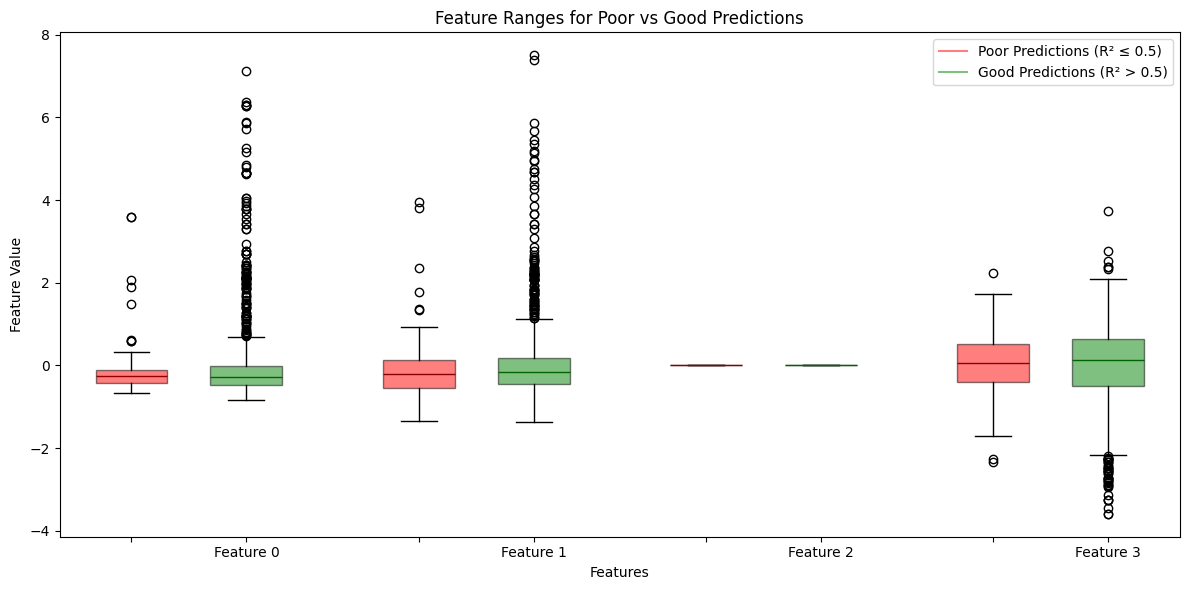

In [391]:
# Create separate dataframes for poor and good predictions
poor_mask = results_df[f'{best_model_name}_r2_score'] <= 0.5
good_mask = ~poor_mask

poor_features = results_df[poor_mask][[f'feature_{i}' for i in range(X_test.shape[1])]]
good_features = results_df[good_mask][[f'feature_{i}' for i in range(X_test.shape[1])]]

# Set up the plot
plt.figure(figsize=(12, 6))

# Create lists to store the data for box plots
poor_data = []
good_data = []
labels = []

# Collect data for each feature
for i in range(X_test.shape[1]):
    poor_data.append(poor_features[f'feature_{i}'])
    good_data.append(good_features[f'feature_{i}'])
    labels.append(f'Feature {i}')

# Create positions for box plots
positions = np.arange(len(labels)) * 2

# Create box plots
bp1 = plt.boxplot(poor_data, positions=positions, patch_artist=True,
                  boxprops=dict(facecolor='red', alpha=0.5),
                  medianprops=dict(color='darkred'),
                  labels=[''] * len(labels))

bp2 = plt.boxplot(good_data, positions=positions + 0.8, patch_artist=True,
                  boxprops=dict(facecolor='green', alpha=0.5),
                  medianprops=dict(color='darkgreen'),
                  labels=labels)

plt.title('Feature Ranges for Poor vs Good Predictions')
plt.ylabel('Feature Value')
plt.xlabel('Features')

# Add legend
plt.plot([], [], color='red', alpha=0.5, label='Poor Predictions (R² ≤ 0.5)')
plt.plot([], [], color='green', alpha=0.5, label='Good Predictions (R² > 0.5)')
plt.legend()

plt.tight_layout()
plt.show()


In [392]:
# Select the best performing model based on out-of-sample R² scores
best_model_name = max(outsample_predictions.keys(), key=lambda k: r2_score(Y_test, outsample_predictions[k]))
model = trained_models[best_model_name]
print(f"Best performing model: {best_model_name}")


Best performing model: Random Forest


In [393]:
# Retrain the best performing model on the full dataset
print(f"Retraining {best_model_name} on full dataset...")
X_full = np.vstack((X_train, X_test))  # Combine training and test features
y_full = np.concatenate((y_train, y_test))  # Combine training and test labels
model.fit(X_full, y_full)
print("Retraining complete.")


Retraining Random Forest on full dataset...
Retraining complete.


## Stacking Model

In [394]:
from sklearn.base import clone

# Define function to clip outliers based on threshold values
def clip_outliers(data, upper_threshold=3, lower_threshold=-2):
    clipped = np.where(data > upper_threshold, upper_threshold, data)
    return np.where(clipped < lower_threshold, lower_threshold, clipped)

# Clip outliers feature by feature
X_full_clipped = X_full.copy()

# Feature 0 (B01)
print("Clipping outliers in B01...")
X_full_clipped[:,0] = clip_outliers(X_full[:,0])

# Feature 1 (B06) 
print("Clipping outliers in B06...")
X_full_clipped[:,1] = clip_outliers(X_full[:,1])

# Feature 2 (NDVI)
print("Clipping outliers in NDVI...")
X_full_clipped[:,2] = clip_outliers(X_full[:,2])

# Create and train a new model of the same type
print(f"\nTraining new {best_model_name} on outlier-clipped data...")
model_clipped = clone(model)  # Create a fresh clone of the best model
model_clipped.fit(X_full_clipped, y_full)
print("Training complete.")


Clipping outliers in B01...
Clipping outliers in B06...
Clipping outliers in NDVI...

Training new Random Forest on outlier-clipped data...
Training complete.


In [395]:
# Calculate in-sample R2 score for the clipped model
r2_clipped = model_clipped.score(X_full_clipped, y_full)
print(f"In-sample R² score for model trained on clipped data: {r2_clipped:.4f}")


In-sample R² score for model trained on clipped data: 0.9696


In [396]:
# Create a stacking model combining predictions from both models using Random Forest
print("Creating stacking model with Random Forest meta-learner...")

# Get predictions from both models
base_predictions = model.predict(X_full)
clipped_predictions = model_clipped.predict(X_full)

# Combine predictions into a feature matrix for meta-learner
meta_features = np.column_stack((base_predictions, clipped_predictions))

# Create and train meta-learner using Random Forest
meta_learner = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)
meta_learner.fit(meta_features, y_full)

print("Random Forest stacking model created and trained.")

# Function to get stacked predictions
def get_stacked_predictions(X):
    # Get base model predictions
    pred1 = model.predict(X)
    pred2 = model_clipped.predict(X)
    
    # Stack predictions
    meta_X = np.column_stack((pred1, pred2))
    
    # Get final predictions from meta-learner
    return meta_learner.predict(meta_X)

print("\nFeature importances in stacking model:")
print(f"Base model importance: {meta_learner.feature_importances_[0]:.4f}")
print(f"Clipped model importance: {meta_learner.feature_importances_[1]:.4f}")



Creating stacking model with Random Forest meta-learner...
Random Forest stacking model created and trained.

Feature importances in stacking model:
Base model importance: 0.8599
Clipped model importance: 0.1401


## Submission

Once you are satisfied with your model, you can proceed to make a submission. To do this, you will need to use your model to predict the Urban Heat Island (UHI) index for a set of test coordinates provided in the <b>"Submission_template.csv"</b> file and upload the results to the challenge platform.

In [397]:
#Reading the coordinates for the submission
test_file = pd.read_csv('submission.csv')
test_file.head()

,Longitude,Latitude,UHI Index
0,-73.971665,40.788763,0.978616
1,-73.971928,40.788875,0.983565
2,-73.967080,40.789080,1.000455
3,-73.972550,40.789082,1.002789
4,-73.969697,40.787953,0.974590


In [398]:
# Mapping satellite data for submission.
# Map both satellite and LST data
val_data = map_satellite_data('S2_sample.tiff', 'submission.csv')
lst_data = map_lst_data('Landsat_LST.tiff', 'submission.csv')

# Join LST data with satellite data
val_data['LST'] = lst_data['LST']

Mapping values:   0%|          | 0/1040 [00:00<?, ?it/s]

Mapping values: 100%|██████████| 1040/1040 [00:00<00:00, 1491.19it/s]


In [399]:
# Calculate NDVI (Normalized Difference Vegetation Index) and handle division by zero by replacing infinities with NaN.
val_data['NDVI'] = (val_data['B08'] - val_data['B04']) / (val_data['B08'] + val_data['B04'])
val_data['NDVI'] = val_data['NDVI'].replace([np.inf, -np.inf], np.nan)  # Replace infinities with NaN

In [400]:
val_data.head()

,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12,LST,NDVI
0,811.0,459.0,617.0,432.0,984.0,2089.0,2405.0,2502.0,2552.0,1474.0,893.0,36.202990,0.705521
1,1208.0,562.0,731.0,647.0,1112.0,2076.0,2248.0,2906.0,2445.0,1751.0,1188.0,36.202990,0.635801
2,899.0,955.0,1052.0,1188.0,979.0,995.0,1158.0,1246.0,1056.0,1101.0,763.0,36.069687,0.023829
3,1193.0,1132.0,1364.0,1512.0,1866.0,1939.0,2076.0,1774.0,2196.0,2521.0,2346.0,36.886594,0.079732
4,1097.0,1506.0,1642.0,1688.0,1294.0,2204.0,2411.0,2834.0,2601.0,2248.0,1848.0,34.500816,0.253428


In [401]:
# Extracting specific columns (B01, B06, and NDVI) from the validation dataset
submission_val_data=val_data.loc[:,['B01','B06','NDVI','LST']]
submission_val_data.head()

,B01,B06,NDVI,LST
0,811.0,2089.0,0.705521,36.202990
1,1208.0,2076.0,0.635801,36.202990
2,899.0,995.0,0.023829,36.069687
3,1193.0,1939.0,0.079732,36.886594
4,1097.0,2204.0,0.253428,34.500816


In [402]:
# Feature Scaling 
submission_val_data = submission_val_data.values
transformed_submission_data = sc.transform(submission_val_data)

In [403]:
#Making predictions using stacking model
final_predictions = get_stacked_predictions(transformed_submission_data)
final_prediction_series = pd.Series(final_predictions)

In [404]:
#Combining the results into dataframe
submission_df = pd.DataFrame({'Longitude':test_file['Longitude'].values, 'Latitude':test_file['Latitude'].values, 'UHI Index':final_prediction_series.values})

In [405]:
#Displaying the sample submission dataframe
submission_df.head()

,Longitude,Latitude,UHI Index
0,-73.971665,40.788763,0.962211
1,-73.971928,40.788875,0.963216
2,-73.967080,40.789080,0.969331
3,-73.972550,40.789082,0.960515
4,-73.969697,40.787953,0.958878


In [406]:
#Dumping the predictions into a csv file.
from datetime import datetime
today = datetime.today().date()

submission_df.to_csv(f"submission-{today}.csv",index = False)

### Upload submission file on platform

Upload the submission.csv on the <a href ="https://challenge.ey.com">platform</a> to get score generated on scoreboard.

## Conclusion

<div align ="justify">Now that you have learned a basic approach to model training, it’s time to try your own approach! Feel free to modify any of the functions presented in this notebook. We look forward to seeing your version of the model and the results. Best of luck with the challenge!</div>